In [13]:
import numpy as np

## Linear Regression

$y = mx + c$

$\text{Loss: }\cfrac{1}{n}\sum(y-y_i)^2$

### Data Sampling

In [154]:
def generate_dataset(size=1000):
    a = 7
    b = 9 
    samples = np.random.normal(10, 10, size) 
    results = a*samples + b - np.random.normal(100, 10, size) 

    return np.column_stack([samples, results])



In [155]:
dataset = generate_dataset(10000)

dataset[:10]

array([[  14.4067296 ,    2.85738158],
       [  -3.99452555, -110.57721881],
       [  17.23947211,   54.76402998],
       [  -2.1654935 ,  -96.61517467],
       [   7.43991819,  -45.10703689],
       [  14.21059704,   17.91915266],
       [   4.5389116 ,  -58.1435132 ],
       [   5.55108655,  -49.91018834],
       [  22.24665482,   90.40142312],
       [  -6.94143026, -132.26847977]])

### Visualise Dataset

In [156]:
import matplotlib.pyplot as plt

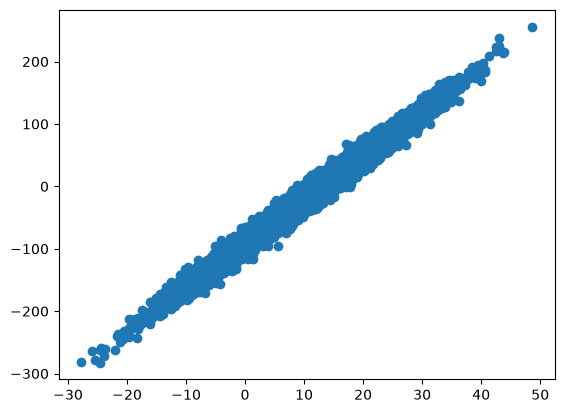

In [157]:
plt.scatter(dataset[:, 0], dataset[:, 1])

### Implementing Linear Regression

In [158]:
w_star, b_star = 0, 0

In [160]:
def loss(y_pred, y_true):
    return np.mean((y_pred - y_true) ** 2)

$\text{Loss: }\cfrac{1}{n}\sum(y-w^*x_i+b^*)^2$


$\text{Loss: }\cfrac{1}{n}[(y-w^*x_i+b^*)^2+(y-w^*x_i+b^*)^2+(y-w^*x_i+b^*)^2+...]$

$\frac{\partial J}{\partial w} = \frac{2}{n}\sum_{i=1}^{n} (\hat{y}_i-y_i)x_i $


In [161]:
def update_weight(current_weight, learning_rate, x, y_true, y_pred):
    difference = np.sum((y_pred - y_true) * x)
    grad = (2/y.shape[0] * difference)
    # print(grad)
    weight = current_weight - learning_rate*grad
    return weight

def update_bias(current_weight, learning_rate, y_true, y_pred):
    difference = np.sum(y_pred - y_true)
    weight = current_weight - learning_rate*((2/y_pred.shape[0])* difference)
    return weight

In [175]:
w = 0
b = 0
x = dataset[:, 0]
y = dataset[:, 1]
weights, biases = [], []
losses = []

for i in range(2000): 
    y_pred = w*x + b
    
    losses.append(loss(y_pred, y))    
    w_new = update_weight(w, 0.001, x, y, y_pred)
    b_new = update_bias(b, 0.001, y, y_pred)
    weights.append(w_new)    
    biases.append(b_new)    

    w = w_new
    b = b_new

print(losses[-10:])

print(w, b)

[np.float64(179.61319957500598), np.float64(179.45509246330886), np.float64(179.2972980607291), np.float64(179.1398157487808), np.float64(178.98264491020166), np.float64(178.82578492894993), np.float64(178.66923519020247), np.float64(178.51299508035203), np.float64(178.35706398700518), np.float64(178.20144129897935)]
6.359766604989612 -78.33517563362915


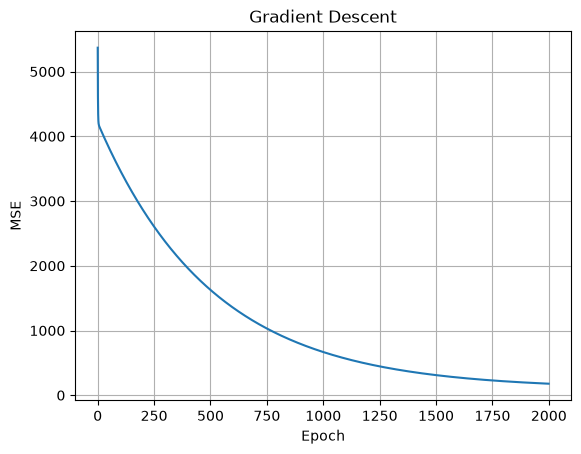

In [176]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Gradient Descent")
plt.grid()
plt.show()

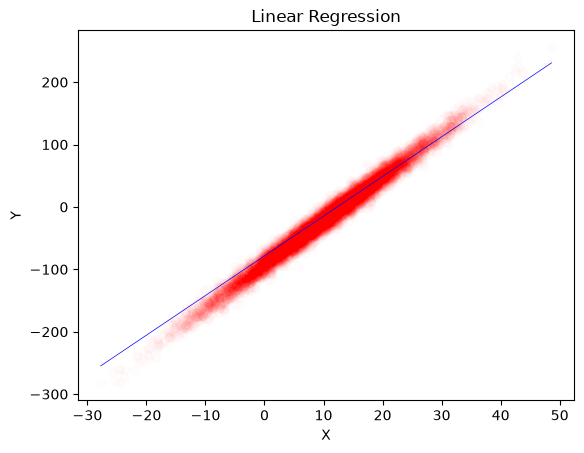

In [177]:
x_line = np.linspace(dataset[:, 0].min(), dataset[:, 0].max(), 100)
y_line = w * x_line + b

plt.plot(dataset[:, 0], dataset[:, 1], 'ro', alpha=0.01)
plt.plot(x_line, y_line, 'b-', linewidth=0.5)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear Regression")
plt.show()

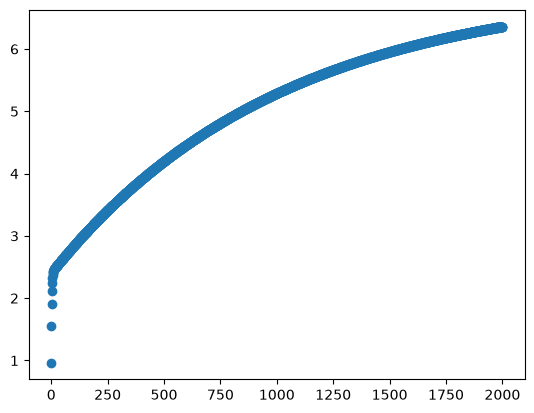

In [178]:
plt.scatter(np.arange(len(weights)), weights)